In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, Matern

In [ ]:
# Original dataset has 10 rows

In [3]:
X = np.load(r"initial_data\function_2\initial_inputs.npy")
Y = np.load(r"initial_data\function_2\initial_outputs.npy")
df = pd.DataFrame({
    'x1': X[:,0],
    'x2': X[:,1],
    'y': Y
})
df.index = df.index+1
df

,x1,x2,y
1,0.665800,0.123969,0.538996
2,0.877791,0.778628,0.420586
3,0.142699,0.349005,-0.065624
4,0.845275,0.711120,0.293993
5,0.454647,0.290455,0.214965
6,0.577713,0.771973,0.023106
7,0.438166,0.685018,0.244619
8,0.341750,0.028698,0.038749
9,0.338648,0.213867,-0.013858
10,0.702637,0.926564,0.611205


In [6]:
print(f'Best output value so far:\n {max(Y)}')
print(f'Corresponding x values:\n {X[np.argmax(Y)]}')
print(f'Best query output: \n Query {np.argmax(Y[10:])+1}: {max(Y[10:])}')
print(f'Improvement over last:\n {max(Y)} - {max(Y[:(len(Y)-1)])} = {max(Y)-max(Y[:(len(Y)-1)])}')

Best output value so far:
 0.7296112502134601
Corresponding x values:
 [0.708638 0.510785]
Best query output: 
 Query 13: 0.7296112502134601
Improvement over last:
 0.7296112502134601 - 0.6822780502943828 = 0.04733319991907725


In [4]:
# Define the GP kernel: a constant (signal variance) scaling a Matern kernel.
# Matern with nu=2.5 gives smooth-but-not-infinitely-smooth functions (less rigid than RBF).
# Passing an array for length_scale makes it ARD (one length scale per input dimension),
# so the GP can learn which inputs matter more. Bounds stop the length scales going to extremes.
kernel = ConstantKernel(1.0) * Matern(      
    length_scale=np.ones(X.shape[1]),    # Starting guess of 1.0 for each input dimension
    length_scale_bounds=(1e-3, 10),      # Allowed range for each length scale during tuning
    nu=2.5                               # Smoothness parameter (twice differentiable)
)
gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=1e-10,                         # Tiny noise term added to the diagonal for numerical stability
    normalize_y=True,                    # Standardise Y (zero mean, unit variance) before fitting
    n_restarts_optimizer=20,             # Re-run hyperparameter optimisation from 20 random starts to avoid poor local optima
    random_state = 42                    # Fixes the random restarts so results are reproducible
)

# Fit the GP to the observed inputs (X) and outputs (Y)
gp.fit(X, Y)

# Randomly sample 10,000 candidate points in the 2-dimensional input space
candidate_points = np.random.rand(10000,2)

# Get the GP's predicted mean and standard deviation (uncertainty) at each candidate
mu, sigma = gp.predict(candidate_points, return_std=True)

# Best observed value so far (we are maximising)
best_y = np.max(Y)
xi = 0   # Exploration parameter: larger values push the search towards more uncertain regions

# Expected gain of each candidate over the current best
improvement = mu - best_y - xi

# Standardised improvement (Z-score), computed only where sigma > 0 to avoid division by zero
Z = np.zeros_like(mu)
mask = sigma > 0
Z[mask] = improvement[mask] / sigma[mask]

# Expected Improvement (EI) formula:
#   improvement * CDF(Z)  -> exploitation (high predicted mean)
#   sigma * PDF(Z)        -> exploration (high uncertainty)
# Points with zero uncertainty keep EI = 0
EI = np.zeros_like(mu)
EI[mask] = (
    improvement[mask] * norm.cdf(Z[mask])
    + sigma[mask] * norm.pdf(Z[mask])
)

# Pick the candidate with the highest EI as the next point to query
next_point = candidate_points[np.argmax(EI)]

print("Next point:", np.round(next_point, 6))

# Sanity check: the GP's prediction at the chosen point
mean, std = gp.predict(next_point.reshape(-1,2), return_std=True)
print(f'Predicted mean: {mean}')
print(f'Predicted std: {std}')

Next point: [0.719878 0.293126]
Predicted mean: [0.68908744]
Predicted std: [0.05444653]


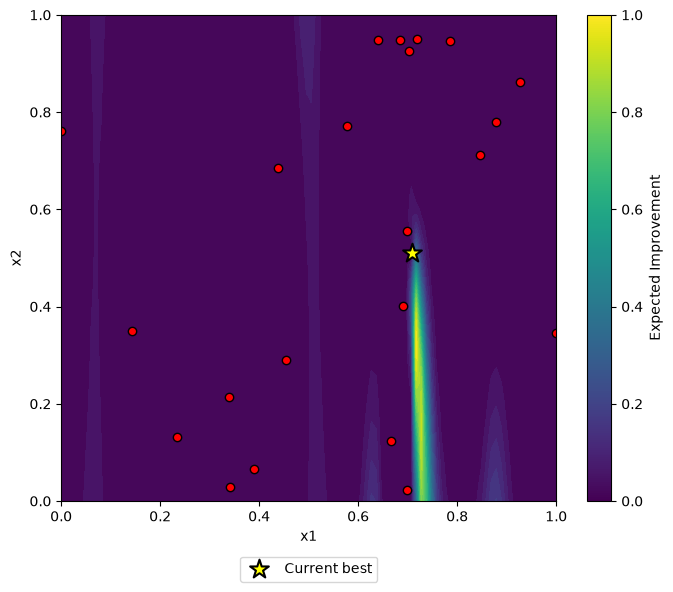

In [ ]:
def plot_EI_slice(gp, X, Y, dim1=0, dim2=1, resolution=100, xi=0):
    """
    Plot a 2D slice of the Expected Improvement acquisition function.

    Parameters
    ----------
    gp : fitted GaussianProcessRegressor
    X : observed inputs (n_samples, n_features)
    Y : observed outputs
    dim1 : first variable to plot
    dim2 : second variable to plot
    """

    # Use the best observed point as the "background": all dimensions not being
    # plotted are held fixed at this point's values
    best_point = X[np.argmax(Y)].copy()

    # Build a regular grid over the unit square for the two chosen dimensions
    x = np.linspace(0, 1, resolution)
    y = np.linspace(0, 1, resolution)

    xx, yy = np.meshgrid(x, y)

    # Create one full-dimensional row per grid cell, each starting as a copy of best_point
    grid = np.tile(best_point, (xx.size, 1))

    # Overwrite just the two plotted dimensions with the grid coordinates
    grid[:, dim1] = xx.ravel()
    grid[:, dim2] = yy.ravel()

    # GP predicted mean and uncertainty at every grid point
    mu, sigma = gp.predict(grid, return_std=True)

    # Best observed value so far (we are maximising)
    best_y = np.max(Y)

    # Expected gain of each grid point over the current best
    improvement = mu - best_y - xi

    EI = np.zeros_like(mu)

    mask = sigma > 0

    # Standardised improvement (Z-score)
    Z = np.zeros_like(mu)
    Z[mask] = improvement[mask] / sigma[mask]

    # Expected Improvement: exploitation term (CDF) + exploration term (PDF)
    EI[mask] = (
        improvement[mask] * norm.cdf(Z[mask])
        + sigma[mask] * norm.pdf(Z[mask])
    )

    plt.figure(figsize=(7,6))

    # Filled contour map of EI across the slice (brighter = higher EI)
    plt.contourf(xx, yy, EI.reshape(xx.shape), levels=30, cmap="viridis")

    # Overlay all observed points, projected onto the two plotted dimensions
    plt.scatter(
        X[:, dim1],
        X[:, dim2],
        c="red",
        edgecolor="black"
    )

    # Highlight the best observed point with a large yellow star
    plt.scatter(
    best_point[dim1],
    best_point[dim2],
    c="yellow",
    edgecolor="black",
    s=200,
    marker="*",
    linewidth=1.5,
    label="Current best"
    )

    plt.xlabel(f"x{dim1+1}")
    plt.ylabel(f"x{dim2+1}")

    plt.colorbar(label="Expected Improvement")
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1))
    plt.tight_layout()
    plt.show()

plot_EI_slice(gp, X, Y, dim1=0, dim2=1)

In [ ]:
'''
1st point selected: [0.784471-0.945866]
Output: -0.0007763761730361918

2nd point selected: [0.684855-0.948501]
Output: 0.5483321201380045

3rd point selected: [0.699448-0.021874]
Output: 0.5826350091466115

4th point selected: [0.718613-0.949323]
Output: 0.5162815607502456

5th point selected: [0.925986-0.861734]
Output: 0.07326985034729352

6th point selected: [0.640772-0.947815]
Output: 0.36943349201630543

7th point selected: [0.000529-0.761309]
Output: 0.003012714397092175

8th point selected: [0.389431-0.065951]
Output: -0.09180471996454886

9th point selected: [0.234436-0.132344]
Output: -0.011459530038986254 

10th point selected: [0.999828-0.344661]
Output: 0.03501938559222839 

11th point selected: [0.698484-0.554508]
Output: 0.6822780502943828   ---NEW BEST--- 

12th point selected: [0.690393-0.401138]
Output: 0.6005758030392903

Final point selected: [0.708638-0.510785]   --- xi lowered to 0 ---
Output: 0.7296112502134601

In [ ]:
# Updating data with new input-output pairs

# X_query1 = np.array([0.784471, 0.945866], dtype=np.float64)
# Y_query1_output = np.array([-0.0007763761730361918], dtype=np.float64)
# X_updated = np.vstack((X, X_query1))
# Y_updated = np.append(Y, Y_query1_output)

# X_query2 = np.array([0.684855,0.948501], dtype=np.float64)
# Y_query2_output = np.array([0.5483321201380045], dtype=np.float64)
# X_updated = np.vstack((X, X_query2))
# Y_updated = np.append(Y, Y_query2_output)

# X_query3 = np.array([0.699448,0.021874], dtype=np.float64)
# Y_query3_output = np.array([0.5826350091466115], dtype=np.float64)
# X_updated = np.vstack((X, X_query3))
# Y_updated = np.append(Y, Y_query3_output)

# X_query4 = np.array([0.718613,0.949323], dtype=np.float64)
# Y_query4_output = np.array([0.5162815607502456], dtype=np.float64)
# X_updated = np.vstack((X, X_query4))
# Y_updated = np.append(Y, Y_query4_output)

# X_query5 = np.array([0.925986,0.861734], dtype=np.float64)
# Y_query5_output = np.array([0.07326985034729352], dtype=np.float64)
# X_updated = np.vstack((X, X_query5))
# Y_updated = np.append(Y, Y_query5_output)

# X_query6 = np.array([0.640772,0.947815], dtype=np.float64)
# Y_query6_output = np.array([0.36943349201630543], dtype=np.float64)
# X_updated = np.vstack((X, X_query6))
# Y_updated = np.append(Y, Y_query6_output)

# X_query7 = np.array([0.000529,0.761309], dtype=np.float64)
# Y_query7_output = np.array([0.003012714397092175], dtype=np.float64)
# X_updated = np.vstack((X, X_query7))
# Y_updated = np.append(Y, Y_query7_output)

# X_query8 = np.array([0.389431,0.065951], dtype=np.float64)
# Y_query8_output = np.array([-0.09180471996454886], dtype=np.float64)
# X_updated = np.vstack((X, X_query8))
# Y_updated = np.append(Y, Y_query8_output)

# X_query9 = np.array([0.234436,0.132344], dtype=np.float64)
# Y_query9_output = np.array([-0.011459530038986254], dtype=np.float64)
# X_updated = np.vstack((X, X_query9))
# Y_updated = np.append(Y, Y_query9_output)

# X_query10 = np.array([0.999828,0.344661], dtype=np.float64)
# Y_query10_output = np.array([0.03501938559222839], dtype=np.float64)
# X_updated = np.vstack((X, X_query10))
# Y_updated = np.append(Y, Y_query10_output)

# X_query11 = np.array([0.698484,0.554508], dtype=np.float64)
# Y_query11_output = np.array([0.6822780502943828], dtype=np.float64)
# X_updated = np.vstack((X, X_query11))
# Y_updated = np.append(Y, Y_query11_output)

# X_query12 = np.array([0.690393,0.401138], dtype=np.float64)
# Y_query12_output = np.array([0.6005758030392903], dtype=np.float64)
# X_updated = np.vstack((X, X_query12))
# Y_updated = np.append(Y, Y_query12_output)

# X_query13 = np.array([0.708638,0.510785], dtype=np.float64)
# Y_query13_output = np.array([0.7296112502134601], dtype=np.float64)
# X_updated = np.vstack((X, X_query13))
# Y_updated = np.append(Y, Y_query13_output)

In [ ]:
# Save new data to original files (initial_inputs.npy & initial_outputs.npy)

# np.save(r"initial_data\function_2\initial_inputs.npy", X_updated)
# np.save(r"initial_data\function_2\initial_outputs.npy", Y_updated)